# 01 Data Preprocessing

Edited by Li Yanyi, Fang Yuyang

Parse, check, clean, and split daily S&P 500 prices.


## 0. Function Definition and Basic Configuration

In [1]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import exchange_calendars as xcals
from datetime import datetime
import numpy as np
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / "01_data_preprocessing.ipynb").is_file():
    raise FileNotFoundError("open it in the *SP500* directory")

### Path Config

In [2]:
DATA_DIR = ROOT / "data"        # main directory

CLEAN_FILE = DATA_DIR / "processed" / "sp500_clean.csv"     # path of cleaned data

RAW_FILE = DATA_DIR / "raw" / "sp500_daily_1996-11-13_to_2026-11-12_raw.json"       # path of raw data

### Table, image and file saving

In [ ]:
def show_figure(fig, path):
    """save and display the charts of this stage."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    display(fig)
    plt.close(fig)

## 1. Parse raw data

Read historical OHLC and volume from [Yahoo Finance](https://finance.yahoo.com/quote/%5EGSPC/history/).


In [ ]:
FIGURE_DIR = ROOT / "output" / "preprocessing"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)


# read raw file
path = RAW_FILE

with path.open(encoding="utf-8") as file:
    data = json.load(file)


# Extract timestamps and daily market trends, align them into a table by position
result = data["chart"]["result"][0]
quote = result["indicators"]["quote"][0]

df = pd.DataFrame({
    "timestamp": result["timestamp"],
    "open": quote["open"],
    "high": quote["high"],
    "low": quote["low"],
    "close": quote["close"],
    "volume": quote["volume"],
})

assert result["meta"]["symbol"] == "^GSPC"      # verify data

display(df.head())

,timestamp,open,high,low,close,volume
0,847895400,729.559998,732.109985,728.030029,731.130005,429840000
1,847981800,731.130005,735.989990,729.200012,735.880005,480350000
2,848068200,735.880005,741.919983,735.150024,737.619995,529100000
3,848327400,737.619995,739.239990,734.390015,737.020020,388520000
4,848413800,737.020020,742.179993,736.869995,742.159973,461980000


## 2. Explore data

Inspect missing values, descriptive statistics, and price distributions.


Sample size 7,547 | Total number of fields 6 | Number of market fields  5


,Field type,Missing quantity
timestamp,int64,0
open,float64,0
high,float64,0
low,float64,0
close,float64,0
volume,int64,0


,count,mean,std,min,5%,25%,50%,75%,95%,max,variance
open,7547.0,2.289552e+03,1.649160e+03,679.280029,8.897050e+02,1.171760e+03,1.452420e+03,2.863495e+03,6.047275e+03,7.813040e+03,2.719728e+06
high,7547.0,2.302620e+03,1.656556e+03,695.270020,8.988690e+02,1.179970e+03,1.461470e+03,2.883200e+03,6.062958e+03,7.844520e+03,2.744178e+06
low,7547.0,2.275607e+03,1.641309e+03,666.789978,8.789190e+02,1.163590e+03,1.441670e+03,2.853070e+03,6.011640e+03,7.805960e+03,2.693895e+06
close,7547.0,2.289967e+03,1.649369e+03,676.530029,8.899150e+02,1.172580e+03,1.452420e+03,2.868800e+03,6.046583e+03,7.818930e+03,2.720418e+06
volume,7547.0,3.187914e+09,1.694166e+09,0.000000,6.247570e+08,1.534300e+09,3.409000e+09,4.241095e+09,5.880013e+09,1.145623e+10,2.870200e+18


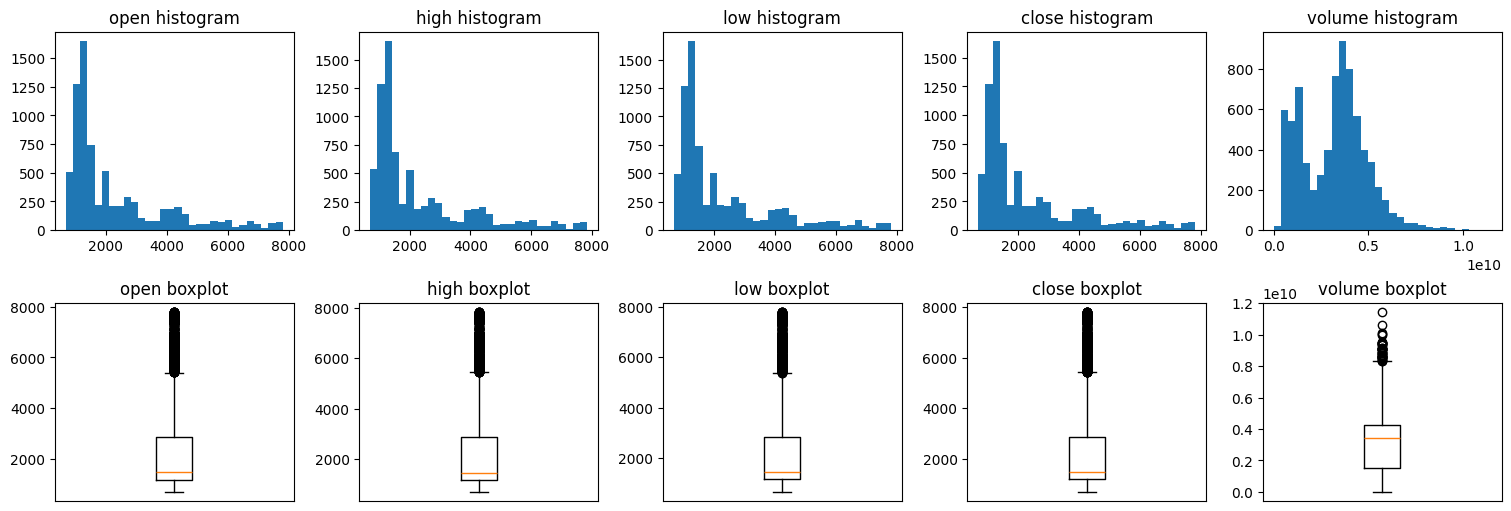

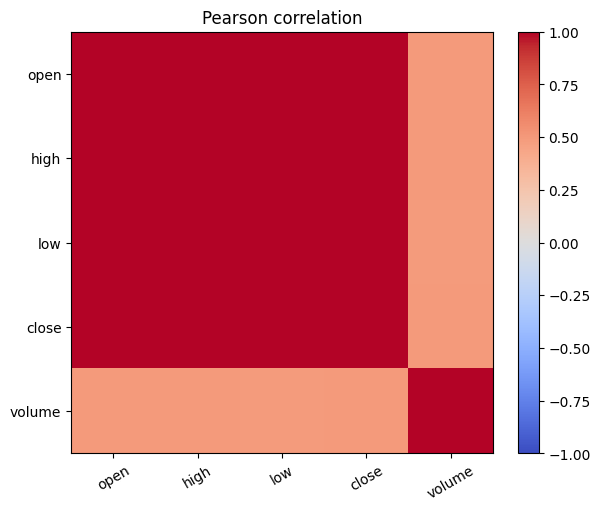

,timestamp,close,volume
6675,1684935000,4115.240234,0


In [5]:
market_cols = ["open", "high", "low", "close", "volume"]
market = df[market_cols]

# view basic infor
print(f"Sample size {len(df):,} | Total number of fields {df.shape[1]} | Number of market fields  {len(market_cols)}")
display(pd.DataFrame({"Field type": df.dtypes, "Missing quantity": df.isna().sum()}))

# descriptive statistics, using **sample variance** for variance
stats = market.describe(percentiles=[0.05, 0.25, 0.50, 0.75, 0.95]).T
stats["variance"] = market.var()
display(stats)

# draw histograms and boxplots for each field
fig, axes = plt.subplots(2, len(market_cols), figsize=(15, 5), layout="constrained")
for i, col in enumerate(market_cols):
    values = market[col].dropna()
    axes[0, i].hist(values, bins=30)
    axes[0, i].set_title(f"{col} histogram")
    axes[1, i].boxplot(values)
    axes[1, i].set_title(f"{col} boxplot")
    axes[1, i].set_xticks([])
show_figure(fig, FIGURE_DIR / "raw_distributions.png")

# calculate Pearson correlation coefficient and draw a heatmap
corr = market.corr()
fig, ax = plt.subplots(figsize=(6, 5), layout="constrained")
heatmap = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(market_cols)), market_cols, rotation=30)
ax.set_yticks(range(len(market_cols)), market_cols)
ax.set_title("Pearson correlation")
fig.colorbar(heatmap, ax=ax)
show_figure(fig, FIGURE_DIR / "raw_correlations.png")

display(df.loc[df["volume"].le(0), ["timestamp", "close", "volume"]])

## 3. Convert dates and types

Use New York trading dates and normalize prices and volume.


In [6]:
# Convert the Unix timestamps from UTC to New York time
df["date"] = (
    pd.to_datetime(df["timestamp"], unit="s", utc=True)  # UTC timestamps precede local trading-date conversion
    .dt.tz_convert("America/New_York")
    .dt.tz_localize(None)
    .dt.normalize()
)

# set the data types for price and trading volume
price_cols = ["open", "high", "low", "close"]
df[price_cols] = df[price_cols].astype("float64")
df["volume"] = df["volume"].astype("Int64")

df = df.sort_values("date", ignore_index=True)
df.head()

,timestamp,open,high,low,close,volume,date
0,847895400,729.559998,732.109985,728.030029,731.130005,429840000,1996-11-13
1,847981800,731.130005,735.989990,729.200012,735.880005,480350000,1996-11-14
2,848068200,735.880005,741.919983,735.150024,737.619995,529100000,1996-11-15
3,848327400,737.619995,739.239990,734.390015,737.020020,388520000,1996-11-18
4,848413800,737.020020,742.179993,736.869995,742.159973,461980000,1996-11-19


## 4. Check trading days

Flag invalid prices and volume; compare dates with NYSE sessions.


In [7]:
# check trading days
start, end = "1996-11-13", "2026-11-12"
nyse = xcals.get_calendar("XNYS", start=start, end=end)     # get the NYSE Trading Calendar
expected = nyse.sessions.tz_localize(None)
actual = pd.DatetimeIndex(df["date"].dropna().unique())

print("Expected trading days", len(expected))
print("Missing trading days", expected.difference(actual).strftime("%Y-%m-%d").tolist())
print("Unexpected dates", actual.difference(expected).strftime("%Y-%m-%d").tolist())

# check duplicate transaction dates
duplicates = df["date"].notna() & df["date"].duplicated(keep=False)
print("Records with duplicate dates", duplicates.sum())
assert not duplicates.any(), "Duplicate trading dates require review."
display(df.loc[duplicates])

# count missing values ​​in each field
display(df.isna().sum().rename("Number of missing values").to_frame())

# check if the price is less than or equal to 0 or infinite
prices = df[["open", "high", "low", "close"]]
bad_price = (prices.le(0) | prices.isin([float("inf"), -float("inf")])).any(axis=1)

# check whether the price is within the normal market range
bad_range = (
    df["low"].gt(df["high"])
    | df["open"].lt(df["low"]) | df["open"].gt(df["high"])
    | df["close"].lt(df["low"]) | df["close"].gt(df["high"])
)

# check if volume is less than or equal to 0
bad_volume = df["volume"].le(0).fillna(False)

print("Records with nonpositive or infinite prices", bad_price.sum())
print("Records with prices outside the valid range", bad_range.sum())
print("Records with volume less than or equal to 0", bad_volume.sum())
display(df.loc[bad_price | bad_range | bad_volume])
# do not delete real market extremes
assert not (bad_price | bad_range).any()
assert not prices.isna().any().any()

Expected trading days 7547
Missing trading days []
Unexpected dates []
Records with duplicate dates 0


,timestamp,open,high,low,close,volume,date


,Number of missing values
timestamp,0
open,0
high,0
low,0
close,0
volume,0
date,0


Records with nonpositive or infinite prices 0
Records with prices outside the valid range 0
Records with volume less than or equal to 0 1


,timestamp,open,high,low,close,volume,date
6675,1684935000,4132.959961,4132.959961,4103.97998,4115.240234,0,2023-05-24


Q1: **Why is it necessary to check trading days?**

The stock market does not trade every day and is closed on weekends, holidays, and some special days. Therefore, it is not possible to directly use a regular calendar to determine whether data is missing, but rather to use the trading calendar of the stock exchange.

Q2: **Why not just delete the outlier directly?**

Financial markets may experience significant fluctuations due to economic crises, unexpected events, and other reasons, and these extreme values may be real and valuable data for research.

## 5. Clean and export

Mark the verified zero volume as missing and check the saved CSV.


In [8]:
df_clean = df.copy()        # copy original data

# mark the verified abnormal trading volume as missing
mask = df_clean["date"].eq(pd.Timestamp("2023-05-24")) & df_clean["volume"].eq(0)  # Only the verified zero-volume date is changed
df_clean.loc[mask, "volume"] = pd.NA
 
price_cols = ["open", "high", "low", "close"]
df_clean[price_cols] = df_clean[price_cols].round(3)        # 3 decimal places

# unified output location
CLEAN_FILE.parent.mkdir(parents=True, exist_ok=True)
df_clean = df_clean.sort_values("date").reset_index(drop=True)
df_clean.to_csv(CLEAN_FILE, index=False, float_format="%.3f", date_format="%Y-%m-%d")
saved = pd.read_csv(CLEAN_FILE, parse_dates=["date"], dtype={"volume": "Int64"})
pd.testing.assert_frame_equal(saved, df_clean, check_dtype=False)
assert len(saved) == 7547
assert saved.loc[saved["volume"].isna(), "date"].tolist() == [pd.Timestamp("2023-05-24")]
display(saved.head())
print(f"Validation passed: {len(saved):,} records, {saved['volume'].isna().sum()} missing volume values.")

,timestamp,open,high,low,close,volume,date
0,847895400,729.56,732.11,728.03,731.13,429840000,1996-11-13
1,847981800,731.13,735.99,729.20,735.88,480350000,1996-11-14
2,848068200,735.88,741.92,735.15,737.62,529100000,1996-11-15
3,848327400,737.62,739.24,734.39,737.02,388520000,1996-11-18
4,848413800,737.02,742.18,736.87,742.16,461980000,1996-11-19


Validation passed: 7,547 records, 1 missing volume values.


## 6. Split by date

Save chronological 8:1:1 EDA splits; training excludes targets crossing boundaries.


In [9]:
split_dir = ROOT / "data" / "splits"
split_dir.mkdir(parents=True, exist_ok=True)

# sort by transaction date and then split in chronological order
data = df_clean.sort_values("date").reset_index(drop=True)  # chronological ordering prevents random mixing

# set dataset partitioning location
n = len(data)
train_end = int(n * 0.8)
val_end = int(n * 0.9)

# split the dataset chronologically
splits = {
    "train": data.iloc[:train_end],
    "val": data.iloc[train_end:val_end],
    "test": data.iloc[val_end:],
}

# confirm that all records have been assigned and that the date ranges of each set do not overlap
assert sum(len(part) for part in splits.values()) == len(data)
assert splits["train"]["date"].max() < splits["val"]["date"].min()
assert splits["val"]["date"].max() < splits["test"]["date"].min()

for name, part in splits.items():
    file = split_dir / f"sp500_{name}.csv"
    part.to_csv(file, index=False, float_format="%.3f", date_format="%Y-%m-%d")

    start, end = part["date"].iloc[[0, -1]].dt.strftime("%Y-%m-%d")
    print(f"{file.name}  {len(part):,} rows  {start} to {end}")

sp500_train.csv  6,037 rows  1996-11-13 to 2020-11-06
sp500_val.csv  755 rows  2020-11-09 to 2023-11-08
sp500_test.csv  755 rows  2023-11-09 to 2026-11-12
